# Checking the combined vote dataset

**Goal:** Confirm `votes_long.parquet` is complete before analysis.

**Data:** 136 federal votes on 49 voting Sundays (2010-2025), municipality level.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_parquet("../data/processed/votes_long.parquet")
national = pd.read_parquet("../data/processed/votes_national.parquet")

print(df.shape, national.shape)
df.head()

(287680, 20) (136, 16)


,date,vote_id,title_en,title_fr,title_de,vote_type_id,main_vote_id,accepted,canton_nr,canton,bfs_nr,municipality,counted,electorate,ballots_cast,valid_votes,yes_votes,no_votes,yes_pct,turnout_pct
0,2010-03-07,5480,Constitutional article on research on humans,Article constitutionnel concernant la recherch...,Verfassungsartikel über die Forschung am Menschen,1,None,True,1,Zürich,1,Aeugst am Albis,True,1262,588,579,476,103,82.210708,46.592710
1,2010-03-07,5480,Constitutional article on research on humans,Article constitutionnel concernant la recherch...,Verfassungsartikel über die Forschung am Menschen,1,None,True,1,Zürich,2,Affoltern am Albis,True,6589,2753,2692,2093,599,77.748886,41.781757
2,2010-03-07,5480,Constitutional article on research on humans,Article constitutionnel concernant la recherch...,Verfassungsartikel über die Forschung am Menschen,1,None,True,1,Zürich,3,Bonstetten,True,3529,1842,1764,1411,353,79.988662,52.196090
3,2010-03-07,5480,Constitutional article on research on humans,Article constitutionnel concernant la recherch...,Verfassungsartikel über die Forschung am Menschen,1,None,True,1,Zürich,4,Hausen am Albis,True,2359,1122,1099,844,255,76.797088,47.562526
4,2010-03-07,5480,Constitutional article on research on humans,Article constitutionnel concernant la recherch...,Verfassungsartikel über die Forschung am Menschen,1,None,True,1,Zürich,5,Hedingen,True,2309,1152,1133,891,242,78.640777,49.891728


In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 287680 entries, 0 to 287679
Data columns (total 20 columns):
 #   Column        Non-Null Count   Dtype         
---  ------        --------------   -----         
 0   date          287680 non-null  datetime64[us]
 1   vote_id       287680 non-null  int64         
 2   title_en      287680 non-null  str           
 3   title_fr      287680 non-null  str           
 4   title_de      287680 non-null  str           
 5   vote_type_id  287680 non-null  int64         
 6   main_vote_id  0 non-null       object        
 7   accepted      287680 non-null  bool          
 8   canton_nr     287680 non-null  int64         
 9   canton        287680 non-null  str           
 10  bfs_nr        287680 non-null  int64         
 11  municipality  287680 non-null  str           
 12  counted       287680 non-null  bool          
 13  electorate    287680 non-null  int64         
 14  ballots_cast  287680 non-null  int64         
 15  valid_votes   287680 non-nul

**Finding:** types load correctly. `main_vote_id` is empty in the source data for every vote, so vote types must be identified with `vote_type_id` instead.

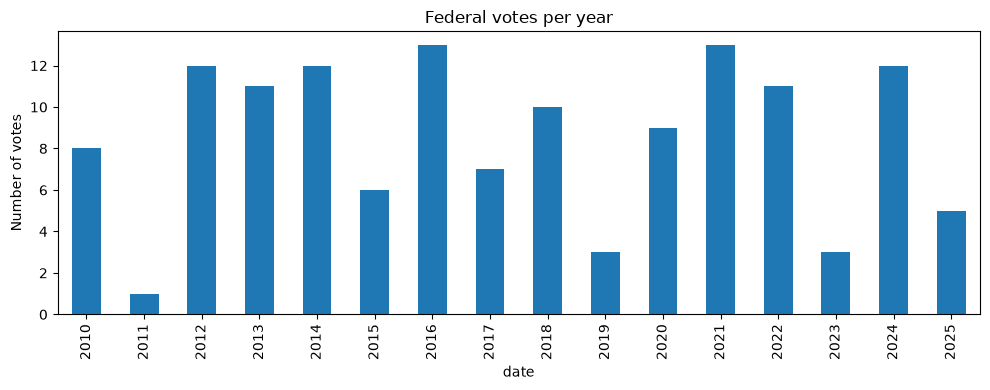

In [3]:
votes_per_year = national.groupby(national["date"].dt.year)["vote_id"].count()

votes_per_year.plot(kind="bar", figsize=(10,4), title="Federal votes per year")
plt.ylabel("Number of votes")
plt.tight_layout()
plt.show()

In [4]:
national.groupby("vote_type_id")["vote_id"].count()

vote_type_id
1    16
2    51
3    66
4     1
5     1
6     1
Name: vote_id, dtype: int64

In [5]:
for type_id, group in national.groupby("vote_type_id"):
    print(f"\n--- vote_type_id {type_id} ({len(group)} votes) ---")
    for title in group["title_en"].head(5):
        print(" ", title)


--- vote_type_id 1 (16 votes) ---
  Constitutional article on research on humans
  Federal resolution on the regulation of gambling for charitable purposes
  Federal decree on the promotion of musical education for young people
  Federal resolution on family policy
  Federal decree on the financing and expansion of the railway infrastructure (direct counterproposal to the popular initiative 'For public transport')

--- vote_type_id 2 (51 votes) ---
  Federal law on occupational old-age, survivors' and invalidity pension provision (BVG) (minimum conversion rate)
  Federal law on compulsory unemployment insurance and insolvency compensation
  Federa law on fixed booked prices
  Amendment to the Federal Health Insurance Act (Managed Care)
  Amendment to the Epizootic Diseases Act (TSG)

--- vote_type_id 3 (66 votes) ---
  Popular initiative ‘Against animal cruelty and for better legal protection of animals’
  Popular initiative ‘For fair taxes. Stop the abuse of tax competition (tax just

**Vote types** (from `vote_type_id`):
- 1 = mandatory referendum (constitutional amendments by parliament): 16 votes
- 2 = optional referendum (laws challenged by 50,000 signatures): 51 votes
- 3 = popular initiative: 66 votes
- 4, 5, 6 = one package on 28 Nov 2010: the expulsion initiative (4), parliament's
  direct counter-proposal (5) and the tie-break question (6): 1 vote each

**Decision:** treat 4 as an initiative and 5 as a mandatory referendum (it amends
the Constitution). drop 6, because it isn't a yes/no question.

In [6]:
n_votes = df["vote_id"].nunique()
appearances = df.groupby("bfs_nr")["vote_id"].nunique()
partial = appearances[appearances < n_votes]
print(f"{len(partial)} units appear in only some votes")

(df[df["bfs_nr"].isin(partial.index)]
   [["bfs_nr", "municipality", "canton"]]
   .drop_duplicates()
   .assign(votes_present=lambda d: d["bfs_nr"].map(partial))
   .sort_values("votes_present"))

6 units appear in only some votes


,bfs_nr,municipality,canton,votes_present
194768,422,Rüti bei Lyssach,Bern / Berne,44
148396,868,Jaberg,Bern / Berne,66
86805,9010,ZH-Ausland-CH,Zürich,95
36677,9100,FR-CH de l'étranger,Fribourg / Freiburg,119
20996,9230,VS-CH de l'étranger,Valais / Wallis,127
7800,9200,TG-Ausland-CH,Thurgau,133


In [7]:
abroad = df[df["municipality"].str.contains("Ausland|étranger|estero", case=False)]
abroad[["bfs_nr", "municipality", "canton"]].drop_duplicates()

,bfs_nr,municipality,canton
566,9030,LU-Ausland-CH,Luzern
586,9040,UR-Ausland-CH,Uri
875,9120,BS-Ausland-CH,Basel-Stadt
1013,9160,AI-Ausland-CH,Appenzell Innerrhoden
1089,9170,SG-Ausland-CH,St. Gallen
1386,9190,AG-Ausland-CH,Aargau
1867,9220,VD-CH de l'étranger,Vaud
2059,9250,GE-CH de l'étranger,Genève
7800,9200,TG-Ausland-CH,Thurgau
20996,9230,VS-CH de l'étranger,Valais / Wallis


**Finding:** 6 units appear in only some votes

In [8]:
summed = df.groupby("vote_id")[["yes_votes", "no_votes"]].sum()
official = national.set_index("vote_id")[["yes_votes", "no_votes"]]

check = summed.join(official, lsuffix="_summed", rsuffix="_official")
check["yes_diff"] = check["yes_votes_official"] - check["yes_votes_summed"]
check["yes_diff_pct"] = 100 * check["yes_diff"] / check["yes_votes_official"]
check["yes_diff_pct"].describe()

count    136.0
mean       0.0
std        0.0
min        0.0
25%        0.0
50%        0.0
75%        0.0
max        0.0
Name: yes_diff_pct, dtype: float64